In [1]:
# Fitrya Irfan_202431073
# Langkah 1 - Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
# Fitrya Irfan_202431073
# Langkah 2 - Membaca dataset
# Dataset : Titanic - Machine Learning from Disaster (Kaggle, train.csv)
# Link    : https://www.kaggle.com/c/titanic
df = pd.read_csv('titanic.csv')
print('Jumlah baris x kolom :', df.shape)
df.head()

Jumlah baris x kolom : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Fitrya Irfan_202431073
# Langkah 2 (lanjutan) - info() dan describe()
df.info()
print()
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB



,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [4]:
# Fitrya Irfan_202431073
# Langkah 3 - Membersihkan data
print('isna().sum() SEBELUM pembersihan:')
print(df.isna().sum())

# PassengerId (nomor urut), Name dan Ticket (identitas unik) tidak punya pola
# yang bisa dipelajari model
# Cabin dibuang karena sekitar 77% isinya kosong
df_bersih = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin']).copy()

# Age (numerik) diisi median, Embarked (kategori) diisi modus
df_bersih['Age'] = df_bersih['Age'].fillna(df_bersih['Age'].median())
df_bersih['Embarked'] = df_bersih['Embarked'].fillna(df_bersih['Embarked'].mode()[0])

print()
print('isna().sum() SESUDAH pembersihan:')
print(df_bersih.isna().sum())

isna().sum() SEBELUM pembersihan:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

isna().sum() SESUDAH pembersihan:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [5]:
# Fitrya Irfan_202431073
# Langkah 4 - Memeriksa target
# Survived = 0 -> penumpang tidak selamat ; Survived = 1 -> penumpang selamat
print('Nilai unik target :', df_bersih['Survived'].unique())
print()
print(df_bersih['Survived'].value_counts())

Nilai unik target : [0 1]

Survived
0    549
1    342
Name: count, dtype: int64


In [6]:
# Fitrya Irfan_202431073
# Langkah 5 - Mengubah target dan fitur kategori menjadi angka dengan LabelEncoder
le_target = LabelEncoder()
le_sex = LabelEncoder()
le_embarked = LabelEncoder()

df_enc = df_bersih.copy()
df_enc['Survived'] = le_target.fit_transform(df_enc['Survived'])
df_enc['Sex'] = le_sex.fit_transform(df_enc['Sex'])
df_enc['Embarked'] = le_embarked.fit_transform(df_enc['Embarked'])

print('Target   (le_target.classes_)  :', le_target.classes_)
print('          -> 0 = tidak selamat, 1 = selamat')
print('Sex      (le_sex.classes_)     :', le_sex.classes_)
print('Embarked (le_embarked.classes_):', le_embarked.classes_)
df_enc.head()

Target   (le_target.classes_)  : [0 1]
          -> 0 = tidak selamat, 1 = selamat
Sex      (le_sex.classes_)     : ['female' 'male']
Embarked (le_embarked.classes_): ['C' 'Q' 'S']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,1,22.0,1,0,7.2500,2
1,1,1,0,38.0,1,0,71.2833,0
2,1,3,0,26.0,0,0,7.9250,2
3,1,1,0,35.0,1,0,53.1000,2
4,0,3,1,35.0,0,0,8.0500,2


In [7]:
# Fitrya Irfan_202431073
# Langkah 6 - Memisahkan fitur dan target, lalu membagi data (test_size = 0.3)
x = df_enc.drop(columns=['Survived'])
y = df_enc['Survived']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

print('Jumlah data latih :', x_train.shape[0])
print('Jumlah data uji   :', x_test.shape[0])
print()
print('Proporsi kelas data latih (%):')
print((y_train.value_counts(normalize=True) * 100).round(2))
print('Proporsi kelas data uji (%):')
print((y_test.value_counts(normalize=True) * 100).round(2))

Jumlah data latih : 623
Jumlah data uji   : 268

Proporsi kelas data latih (%):
Survived
0    61.16
1    38.84
Name: proportion, dtype: float64
Proporsi kelas data uji (%):
Survived
0    62.69
1    37.31
Name: proportion, dtype: float64


In [8]:
# Fitrya Irfan_202431073
# Langkah 7 - Pipeline StandardScaler + SVC (scaler di dalam pipeline)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC())
])
print(pipe)

Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC())])


In [9]:
# Fitrya Irfan_202431073
# Langkah 8 - Grid parameter
param_grid = {
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1]
}
jumlah_kombinasi = 1
for nilai in param_grid.values():
    jumlah_kombinasi *= len(nilai)
print('Jumlah kombinasi parameter :', jumlah_kombinasi, '(3 x 4 x 4)')
print('Total pelatihan dengan cv = 5 :', jumlah_kombinasi * 5)

Jumlah kombinasi parameter : 48 (3 x 4 x 4)
Total pelatihan dengan cv = 5 : 240


In [10]:
# Fitrya Irfan_202431073
# Langkah 9 - GridSearchCV (cv = 5, scoring = 'accuracy') pada data latih
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(x_train, y_train)

print('Parameter terbaik            :', grid.best_params_)
print('Skor validasi silang terbaik :', round(grid.best_score_, 4))

Parameter terbaik            : {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Skor validasi silang terbaik : 0.8283


In [11]:
# Fitrya Irfan_202431073
# Langkah 10 - Kandidat peringkat pertama pada cv_results_
cv = pd.DataFrame(grid.cv_results_)
kolom = ['param_svc__kernel', 'param_svc__C', 'param_svc__gamma',
         'mean_test_score', 'rank_test_score']
peringkat1 = cv[cv['rank_test_score'] == 1][kolom]
print('Jumlah kandidat peringkat 1 :', len(peringkat1))
peringkat1

Jumlah kandidat peringkat 1 : 1


,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,rank_test_score
40,rbf,100.0,0.01,0.828284,1


In [12]:
# Fitrya Irfan_202431073
# Langkah 11 - Evaluasi model akhir pada data latih dan data uji
model_akhir = grid.best_estimator_
y_pred_train = model_akhir.predict(x_train)
y_pred_test = model_akhir.predict(x_test)

nama_kelas = ['Tidak selamat (0)', 'Selamat (1)']
print('Accuracy data latih :', round(accuracy_score(y_train, y_pred_train), 4))
print('Accuracy data uji   :', round(accuracy_score(y_test, y_pred_test), 4))
print()
print('Confusion matrix data latih:')
print(confusion_matrix(y_train, y_pred_train))
print('Confusion matrix data uji:')
print(confusion_matrix(y_test, y_pred_test))
print()
print('Classification report data uji:')
print(classification_report(y_test, y_pred_test, target_names=nama_kelas))

Accuracy data latih : 0.8347
Accuracy data uji   : 0.8134

Confusion matrix data latih:
[[347  34]
 [ 69 173]]
Confusion matrix data uji:
[[147  21]
 [ 29  71]]

Classification report data uji:
                   precision    recall  f1-score   support

Tidak selamat (0)       0.84      0.88      0.85       168
      Selamat (1)       0.77      0.71      0.74       100

         accuracy                           0.81       268
        macro avg       0.80      0.79      0.80       268
     weighted avg       0.81      0.81      0.81       268



In [13]:
# Fitrya Irfan_202431073
# Langkah 12 - Analisis margin pada dua dimensi (fitur Age dan Fare)
# Target sudah biner, jadi kedua kelas dipakai
x2_train = x_train[['Age', 'Fare']]
sc2 = StandardScaler()
x2_scaled = sc2.fit_transform(x2_train)

svm2d = SVC(kernel='linear', C=1)
svm2d.fit(x2_scaled, y_train)

w = svm2d.coef_[0]
margin = 2 / np.linalg.norm(w)

print('coef_ (w)    :', svm2d.coef_.round(4))
print('intercept_ (b) :', svm2d.intercept_.round(4))
print('n_support_   :', svm2d.n_support_, '(jumlah support vector kelas 0 dan 1)')
print('Margin = 2/||w|| :', round(margin, 4))
print('Akurasi model 2D pada data latih :', round(svm2d.score(x2_scaled, y_train), 4))

coef_ (w)    : [[-0.0715  0.7821]]
intercept_ (b) : [-0.638]
n_support_   : [229 228] (jumlah support vector kelas 0 dan 1)
Margin = 2/||w|| : 2.5465
Akurasi model 2D pada data latih : 0.6485


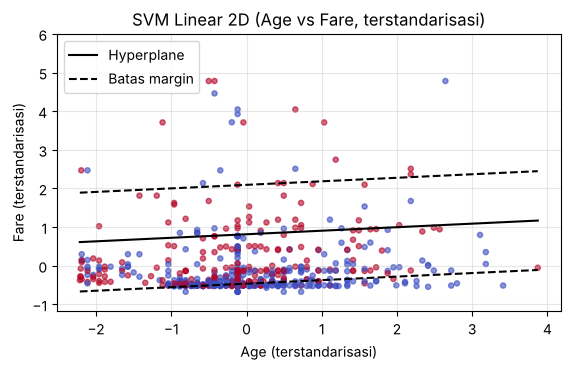

In [14]:
# Fitrya Irfan_202431073
# Langkah 12 (lanjutan) - Visualisasi garis pemisah dan margin
plt.figure(figsize=(6.5, 3.6))
plt.scatter(x2_scaled[:, 0], x2_scaled[:, 1], c=y_train,
            cmap='coolwarm', s=14, alpha=0.6)

xx = np.linspace(x2_scaled[:, 0].min(), x2_scaled[:, 0].max(), 100)
yy = -(w[0] * xx + svm2d.intercept_[0]) / w[1]
yy_atas = -(w[0] * xx + svm2d.intercept_[0] - 1) / w[1]
yy_bawah = -(w[0] * xx + svm2d.intercept_[0] + 1) / w[1]
plt.plot(xx, yy, 'k-', label='Hyperplane')
plt.plot(xx, yy_atas, 'k--', label='Batas margin')
plt.plot(xx, yy_bawah, 'k--')
plt.ylim(x2_scaled[:, 1].min() - 0.5, 6)
plt.title('SVM Linear 2D (Age vs Fare, terstandarisasi)')
plt.xlabel('Age (terstandarisasi)')
plt.ylabel('Fare (terstandarisasi)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
# Fitrya Irfan_202431073
# Uji satu data baru - mengambil satu baris dari data uji
baris = x_test.iloc[[0]]
print('Data yang diuji:')
print(baris.to_string())
print()

dalam_rentang = (baris.iloc[0] >= x_train.min()) & (baris.iloc[0] <= x_train.max())
print('Fitur berada dalam rentang data latih:')
print(dalam_rentang.to_string())
print('Semua fitur dalam rentang :', bool(dalam_rentang.all()))
print()

prediksi = model_akhir.predict(baris)[0]
print('Prediksi model :', prediksi, '->', nama_kelas[prediksi])
print('Label sebenarnya :', y_test.iloc[0], '->', nama_kelas[y_test.iloc[0]])

Data yang diuji:
     Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
495       3    1  28.0      0      0  14.4583         0

Fitur berada dalam rentang data latih:
Pclass      True
Sex         True
Age         True
SibSp       True
Parch       True
Fare        True
Embarked    True
Semua fitur dalam rentang : True

Prediksi model : 0 -> Tidak selamat (0)
Label sebenarnya : 0 -> Tidak selamat (0)
